# Case Study 27 — From 10 Million Call Minutes to Decisions: Intent Frequency, Compliance Monitoring and a Cluster-Randomised Dialler Test

**Priority:** ★ Optional · **Reference:** Case Study 27 — *Policybazaar: speech analytics, request-frequency insight and dialler analytics* (`indian_fintech_data_science_case_studies.md`)
**Audience:** Head of Sales Operations, Quality & Compliance, Product (health insurance), Contact-centre analytics
**Data:** ⚠️ **SYNTHETIC** (D-27-01). Call audio and dialler logs are confidential. We simulate the *outputs* an analytics team works with, not audio.
**Reproducibility:** seed = 42 · `python -m nbconvert --to notebook --execute --inplace cs27_call_analytics_dialler.ipynb`

## 0. Executive Summary for Business

*(Synthetic transcript-derived records and a simulated dialler experiment; Policybazaar disclosed no ASR error rates or experiment design. Written after the analysis.)*

- **The question:** can transcript-based request counts guide product decisions, can the compliance flag cover 100% of calls usefully, and did the new dialler really cause the efficiency gain?
- **Intent counts are usable for ranking, not for exact shares.** The ASR + NLP pipeline tags intent correctly **70%** of the time (Hindi 64%, Hinglish 71%, English 81%). Despite that, the documented insight survives: "cashless hospital" is **7th in the transcripts (95% range 7–9) and truly 8th**, with a predicted share of 6.5% against a true 5.6%. It is also **growing about 5% a week** (trend p ≈ 1e-24), which is the product signal that mattered. A confusion-matrix correction did not remove the bias for this class (corrected 6.5%, CI 5.1–7.9%, which does include the truth), so quote ranges, not exact shares.
- **Compliance flags beat random sampling by a mile.** The breach score has ROC-AUC **0.92** (similar across languages). At a 5% alert budget, **62% of alerts are real breaches** (vs 6.4% by chance) and **48% of all breaches are caught**, against 5% with random listening. At a 1–2% budget (today's human capacity), precision is 82–90%.
- **The dialler gain is real, and a proper analysis shows how much.** Teams were randomised (12 new, 12 old), so the team is the unit.
  - **Dials per hour:** +32% (18.0 → 23.9).
  - **Talk-time share ("call efficiency"):** 40% → **60%**, below the documented 85%.
  - **Connect rate:** +16%.
  - **Sales per logged-in hour:** +66%.
  - **Callback delay:** 295 → 45 minutes.
  - All permutation p < 0.0001.
  - Treating the 4,740 agent-days as independent would have understated the uncertainty by 2.2×.
- **₹ impact (400 outbound agents):** ≈ **₹2.6 crore/month of extra margin (range ₹2.2–3.1 crore)**, equivalent to the output of ≈ 260 more agents. QA at a 5% alert budget on 10 lakh calls finds ≈ 31,000 true breaches for ≈ ₹0.17 crore, against ≈ 1,000 under 1–2% random listening.
- **I recommend:**
  - Roll out the new dialler to all teams.
  - Run compliance QA from flagged calls with a fixed alert budget.
  - Report intent shares as ranges and re-estimate the correction as the product mix changes.
  - Measure WER by language on a labelled sample.

## 1. The Problem in Simple English

A large insurance marketplace handles ~**10 million call minutes a month**. Humans could listen to only **1–2%** of them. A speech-to-text engine (for Hindi, English and mixed "Hinglish") plus language analysis turns every call into text and tags. That unlocks three uses:
1. **What are customers asking for?** A simple count of request types showed that **cashless-hospital requests** were the 7th–8th most common, which led to a product (a cashless-hospital integration).
2. **Are agents following the rules?** Real-time alerts for compliance breaches and mis-selling, on 100% of calls instead of 1–2%.
3. **Can the dialler be more efficient?** More dials, more connects, shorter callbacks, and less idle time.

The data-science questions: how accurate is the transcript-derived intent (and is that count *reliable enough* to drive a product decision), how well does the compliance flag work, and **did the dialler change really cause the reported efficiency gain**, tested in an experiment with teams as the unit?

## 2. Reference from the Case File

### (a) What Policybazaar did — *documented*

| Item | Documented fact (quoted from the reference file) |
|---|---|
| Problem | "Only 1–2% of about 10 million monthly call minutes could be quality-checked by humans"; "nearly 100 million customer queries over the phone in 2017" |
| Question | What are customers asking for? Where are agents breaking compliance or mis-selling? How can dialler efficiency be improved? |
| Data | Call audio (~10M minutes/month, Hindi and English); dialler logs (dial-outs, connects, callbacks) |
| Approach | Proprietary Hindi voice-to-text (third-party tools "inadequate") → NLP → real-time alerts for compliance breaches and pitch mismatches → request-frequency analysis → dialler analytics |
| Statistics | Frequency ranking of request types: **cashless hospital requests were the 7th–8th most common** |
| ML | In-house ASR + NLP; **WER and validation ND**; TensorFlow, SageMaker, GPUs |
| Impact | Dialler: "**50%** increase in dial-out rates"; call efficiency **40% → 85%**; callback time cut to 30–45 minutes |

**Source:** AWS case study / press coverage on Policybazaar (links in the reference file).

### (b) What *we* simulate and add

| Item | Our choice |
|---|---|
| Part A | 60,000 inbound calls over 12 weeks with an ASR+NLP **predicted intent** (13 intents) vs the hidden true intent; error rates depend on language (Hindi worst); cashless-hospital requests **rise over the 12 weeks** |
| Part B | 8,000 calls re-listened by QA vs the model's compliance-breach score (6% true breaches) |
| Part C | 120 agents in 24 teams × 40 days; **cluster-randomised** (12 teams new dialler, 12 old); outcomes: dials, connects, talk time, sales, callback delay |
| Statistics added | Intent accuracy and per-intent F1 with bootstrap CIs; ranking uncertainty (**rank CIs by bootstrap**); correction of frequencies for classifier confusion (**matrix inversion**); trend test for a rising intent; compliance flag PR/ROC and **alert budget**; **team-level cluster analysis** of the dialler (permutation test, mixed model, cluster-robust SE, ICC, design effect); callbacks; ₹ |

### (c) How the industry uses this

Speech analytics is mainstream in Indian BFSI contact centres (Policybazaar, Bajaj Finserv, HDFC Bank, Airtel). Vendors include Observe.AI, Uniphore, Skit.ai and in-house Indic ASR. **Intent counts drive product roadmaps; QA flags drive compliance (IRDAI call-recording and mis-selling norms); dialler settings drive productivity.** Each needs its own validation, which is what this notebook does.

## 3. Business Question → Analytical Question → Statistical Hypotheses

| Level | Statement |
|---|---|
| Business | Can we trust transcript-based request counts to drive product decisions, rely on the compliance flag for QA, and prove the new dialler increases efficiency? |
| Analytical | (1) How accurate and how biased are intent counts, and is the rank of "cashless hospital" reliable? (2) What alert budget gives useful compliance QA? (3) What is the causal effect of the new dialler on dials, talk time and sales, with teams as the unit of randomisation? |

**Hypotheses**
- **H1:** H0: intent accuracy does not differ by language (χ²).
- **H2:** H0: the weekly share of cashless-hospital requests has no trend (Cochran–Armitage, on corrected shares).
- **H3:** H0: the compliance flag's precision at a 5% alert budget ≤ the base rate (6%).
- **H4:** H0: the new dialler has no effect on talk-time share / sales per agent-day (team-level permutation test and cluster-robust regression).

**Primary metric (dialler):** sales per logged-in hour, with **talk-time share** (call efficiency) as the documented mechanism. **Unit of randomisation: team** (24), so effective n is 24, not 4,800 agent-days.

In [1]:
import sys, warnings, importlib, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.formula.api as smf
from sklearn.metrics import f1_score, accuracy_score, confusion_matrix, roc_auc_score, precision_recall_curve
from statsmodels.stats.proportion import proportion_confint
from statsmodels.stats.multitest import multipletests

SEED = 42
np.random.seed(SEED)
RNG = np.random.default_rng(np.random.SeedSequence(SEED).spawn(1)[0])
warnings.filterwarnings("ignore")
pd.set_option("display.width", 170, "display.max_columns", 30, "display.float_format", "{:,.4f}".format)
sns.set_theme(style="whitegrid"); plt.rcParams.update({"figure.figsize": (10, 4.5), "figure.dpi": 110, "axes.titleweight": "bold"})
print("ready")

ready


## 4. Data

### 4.1 Sourcing outcome

| Attempt | Result |
|---|---|
| Public Indian contact-centre call logs, intents and dialler logs | **None.** Call recordings and dialler data are confidential and personal. Public Indic speech corpora (e.g., Mozilla Common Voice Hindi, IndicTTS) have no business intents or dialler logs. |
| **Decision** | Simulated transcript-derived intents, QA audit records and a cluster-randomised dialler experiment (D-27-01) |

### 4.2 Generator — clearly marked section

In [2]:
%%writefile data/generate_cs27.py
"""
SYNTHETIC DATA GENERATOR - CASE STUDY 27 (Policybazaar-style call analytics, intent frequency and dialler efficiency)
====================================================================================================================
THIS DATA IS SYNTHETIC. Call audio and dialler logs are confidential. We do not simulate audio; we simulate the
OUTPUTS and records an analytics team works with.

Part A - intent frequency: 60,000 inbound customer calls, each with a transcript-derived INTENT from an ASR+NLP
pipeline (with confusions, and Hindi-vs-English word error rates). The true intent mix includes "cashless hospital
network request" as a mid-ranked intent that is easy to under-count (rare in the pre-period, rising over 12 weeks).
Part B - compliance QA: 8,000 calls re-listened by QA (gold), with the model's compliance-breach / mis-selling flag.
Part C - dialler experiment: 8 weeks of outbound dialling by 120 agents in teams; a RANDOMISED switch from a
"static list" dialler to a "predictive / adaptive" dialler by team (cluster-randomised, 24 teams), plus callback
scheduling. Outcomes per agent-day: dials, connects, talk time, wrap time, idle time, sales, callbacks and
callback delay. Call efficiency = talk time share of logged-in time.

Calibration anchors (reference file, Case Study 27): "only 1-2% of ~10 million monthly call minutes could be
quality-checked"; cashless-hospital requests the "7th-8th most common"; dialler "50% increase in dial-out rates",
"call efficiency 40% -> 85%", "callback time 30-45 minutes"; WER ND. Rates are our assumptions (D-27-02).
Hidden truth columns start with "_".

Outputs: data/cs27/calls.csv.gz, data/cs27/qa_audit.csv.gz, data/cs27/dialler_agent_days.csv.gz
"""
import os
import numpy as np
import pandas as pd
from scipy.special import expit

SEED = 42
INTENTS = ["renewal_reminder", "premium_quote", "policy_status", "claim_status", "payment_issue", "document_request", "cashless_hospital", "coverage_query",
           "cancellation_refund", "portability", "endorsement", "agent_complaint", "other"]
P0 = np.array([0.20, 0.17, 0.12, 0.10, 0.08, 0.07, 0.035, 0.07, 0.05, 0.03, 0.04, 0.02, 0.045])


def generate(seed=SEED):
    rng = np.random.default_rng(seed)
    # ---- Part A: intents over 12 weeks ----
    n = 60_000; week = rng.integers(1, 13, n); lang = rng.choice(["hindi", "english", "hinglish"], n, p=[0.45, 0.25, 0.30])
    rows = []
    P = np.tile(P0, (12, 1)); P[:, INTENTS.index("cashless_hospital")] *= 1 + 0.13 * np.arange(12); P = P / P.sum(1, keepdims=True)           # cashless requests grow
    true_i = np.array([rng.choice(len(INTENTS), p=P[w - 1]) for w in week])
    wer = pd.Series(lang).map({"hindi": 0.22, "english": 0.09, "hinglish": 0.17}).values * np.exp(rng.normal(0, 0.3, n))
    p_ok = np.clip(0.93 - 1.3 * wer, 0.35, 0.99)
    ok = rng.random(n) < p_ok; confuse = np.array([rng.choice([j for j in range(len(INTENTS)) if j != t], p=None) if True else t for t in true_i])
    near = {"claim_status": "cashless_hospital", "cashless_hospital": "claim_status", "premium_quote": "coverage_query", "coverage_query": "premium_quote",
            "policy_status": "document_request", "document_request": "policy_status", "renewal_reminder": "premium_quote", "payment_issue": "policy_status", "portability": "coverage_query"}
    pred = np.where(ok, true_i, np.where(rng.random(n) < 0.55, [INTENTS.index(near.get(INTENTS[t], "other")) for t in true_i], confuse))
    dur = np.round(np.exp(rng.normal(np.log(5.5), 0.6, n)), 1)
    calls = pd.DataFrame({"call_id": [f"CALL{i:06d}" for i in range(n)], "week": week, "language": lang, "duration_min": dur, "asr_wer": wer.round(3),
                          "predicted_intent": np.array(INTENTS)[pred], "_true_intent": np.array(INTENTS)[true_i]})
    # ---- Part B: compliance QA ----
    m = 8000; breach = rng.random(m) < 0.06; sc = np.where(breach, rng.beta(4, 3, m), rng.beta(2, 6, m))
    qa = pd.DataFrame({"call_id": [f"QA{i:05d}" for i in range(m)], "qa_breach": breach.astype(int), "model_breach_score": sc.round(3), "language": rng.choice(["hindi", "english", "hinglish"], m, p=[0.45, 0.25, 0.30])})
    # ---- Part C: cluster-randomised dialler ----
    teams = np.repeat(np.arange(24), 5); arm = np.zeros(24, int); arm[rng.permutation(24)[:12]] = 1
    rows = []
    agent_skill = rng.normal(0, 0.25, 120)
    team_eff = rng.normal(0, 0.12, 24)
    for a in range(120):
        t = teams[a]; tr = arm[t]
        for d in range(40):
            logged = 480 * np.exp(rng.normal(0, 0.05))
            connect_rate = np.clip(0.26 + 0.04 * tr + 0.05 * agent_skill[a] + rng.normal(0, 0.03), 0.05, 0.6)
            dial_rate_h = np.exp(np.log(22) + 0.28 * tr * (1 + 0.1 * team_eff[t]) + 0.1 * agent_skill[a] + rng.normal(0, 0.1))            # dials per hour (+~32% with predictive dialler)
            dials = int(rng.poisson(dial_rate_h * 6.5)); conn = rng.binomial(dials, connect_rate)
            talk_share = np.clip(0.40 + 0.20 * tr + 0.08 * agent_skill[a] + team_eff[t] * 0.2 + rng.normal(0, 0.05), 0.15, 0.9)
            talk = logged * talk_share; sales = rng.binomial(conn, np.clip(0.055 + 0.012 * agent_skill[a] + 0.004 * tr, 0.01, 0.2))
            cb_delay = np.exp(rng.normal(np.log(260 if tr == 0 else 40), 0.5))                                                          # callback delay minutes
            rows.append((f"AG{a:03d}", f"T{t:02d}", tr, d + 1, round(logged), dials, conn, round(talk), sales, round(cb_delay, 1), round(logged - talk)))
    dl = pd.DataFrame(rows, columns=["agent_id", "team_id", "new_dialler", "day", "logged_in_min", "dials", "connects", "talk_min", "sales", "avg_callback_delay_min", "non_talk_min"])
    # data-quality defects
    calls.loc[calls.sample(n=250, random_state=seed).index, "predicted_intent"] = ""                    # ASR failed
    calls = pd.concat([calls, calls.sample(n=300, random_state=seed + 1)], ignore_index=True)
    dl.loc[dl.sample(n=60, random_state=seed + 2).index, "logged_in_min"] = 0                           # agents logged in via the wrong ID
    return calls, qa, dl


if __name__ == "__main__":
    here = os.path.dirname(os.path.abspath(__file__)); os.makedirs(os.path.join(here, "cs27"), exist_ok=True)
    c, q, d = generate(); c.to_csv(os.path.join(here, "cs27", "calls.csv.gz"), index=False); q.to_csv(os.path.join(here, "cs27", "qa_audit.csv.gz"), index=False); d.to_csv(os.path.join(here, "cs27", "dialler_agent_days.csv.gz"), index=False)
    cc = c.drop_duplicates("call_id"); print("intent accuracy", (cc.predicted_intent == cc._true_intent).mean().round(4))
    print(cc._true_intent.value_counts().rank(ascending=False)["cashless_hospital"], cc.predicted_intent.value_counts().rank(ascending=False).get("cashless_hospital"))
    print(d[d.logged_in_min > 0].groupby("new_dialler").agg(dials=("dials", "mean"), talk=("talk_min", "mean"), li=("logged_in_min", "mean"), sales=("sales", "mean")).round(2))

Overwriting data/generate_cs27.py


In [3]:
os.makedirs("data/cs27", exist_ok=True)
sys.path.insert(0, "data"); import generate_cs27 as gen; importlib.reload(gen)
calls_raw, qa, dl_raw = gen.generate(seed=SEED)
calls_raw.to_csv("data/cs27/calls.csv.gz", index=False); qa.to_csv("data/cs27/qa_audit.csv.gz", index=False); dl_raw.to_csv("data/cs27/dialler_agent_days.csv.gz", index=False)
print(f"calls: {len(calls_raw):,} rows ({calls_raw.call_id.nunique():,} unique) | QA audit: {len(qa):,} | dialler: {len(dl_raw):,} agent-days, {dl_raw.agent_id.nunique()} agents, {dl_raw.team_id.nunique()} teams")
calls_raw.drop(columns=["_true_intent"]).sample(3, random_state=SEED).T

calls: 60,300 rows (60,000 unique) | QA audit: 8,000 | dialler: 4,800 agent-days, 120 agents, 24 teams


,53167,46547,34405
call_id,CALL053167,CALL046547,CALL034405
week,1,10,8
language,hindi,hindi,hindi
duration_min,7.3000,15.6000,8.4000
asr_wer,0.4100,0.2140,0.1870
predicted_intent,premium_quote,document_request,document_request


| Parameter | Value | Basis |
|---|---|---|
| Calls | 60,000 over 12 weeks; Hindi 45% / English 25% / Hinglish 30%; mean duration 5.5 min | Our assumption; **documented** Hindi and English |
| Intents | 13 types; cashless-hospital ≈ 3.5% rising ~13% per week | **Documented** 7th–8th most common |
| ASR/NLP | Accuracy falls with word-error rate (WER: Hindi 22%, Hinglish 17%, English 9%); confusions concentrate on similar intents (claim status ↔ cashless hospital) | Typical Indic ASR behaviour; **WER ND in the source** |
| QA audit | 8,000 re-listened calls, 6% true breaches | Our assumption |
| Dialler experiment | 24 teams × 5 agents × 40 days; 12 teams get the new dialler (randomised); ≈ +32% dials/hour, talk share 40% → 60%, callback delay 260 → 40 minutes | **Documented** direction ("+50% dial-out", "efficiency 40% → 85%", "callback 30–45 min"); sizes ours |
| DQ issues | 300 duplicate calls; 250 ASR failures (blank intent); 60 agent-days logged under the wrong ID (0 logged-in minutes) | Built-in messiness |

### 4.3 Data dictionary

In [4]:
dd = pd.DataFrame([
    ("calls: call_id, week, language, duration_min, asr_wer", "Call, week, language, length, word-error rate"), ("predicted_intent", "Intent from ASR + NLP (blank = ASR failure)"),
    ("_true_intent", "HIDDEN true intent"), ("qa_audit: qa_breach, model_breach_score", "QA re-listen result; model's breach score"),
    ("dialler: agent_id, team_id, new_dialler, day", "Agent-day; the team's randomised arm"), ("logged_in_min, dials, connects, talk_min, non_talk_min, sales", "Daily activity and outcomes"),
    ("avg_callback_delay_min", "Average delay before a requested callback was made"),
], columns=["field(s)", "meaning"])
dd.to_csv("data/cs27/data_dictionary.csv", index=False); dd

,field(s),meaning
0,"calls: call_id, week, language, duration_min, ...","Call, week, language, length, word-error rate"
1,predicted_intent,Intent from ASR + NLP (blank = ASR failure)
2,_true_intent,HIDDEN true intent
3,"qa_audit: qa_breach, model_breach_score",QA re-listen result; model's breach score
4,"dialler: agent_id, team_id, new_dialler, day",Agent-day; the team's randomised arm
5,"logged_in_min, dials, connects, talk_min, non_...",Daily activity and outcomes
6,avg_callback_delay_min,Average delay before a requested callback was ...


## 5. Data Quality Checks

In [5]:
checks = {"duplicate calls": int(calls_raw.call_id.duplicated().sum()), "ASR failures (blank intent)": int((calls_raw.drop_duplicates("call_id").predicted_intent.fillna("") == "").sum()),
          "agent-days with 0 logged-in minutes (wrong ID)": int((dl_raw.logged_in_min == 0).sum()), "connects > dials": int((dl_raw.connects > dl_raw.dials).sum())}
print(pd.Series(checks, name="rows").to_string())
calls = calls_raw.drop_duplicates("call_id").copy(); calls["predicted_intent"] = calls.predicted_intent.fillna("")
asr_fail = calls.predicted_intent == ""; cl = calls[~asr_fail].copy()
dl = dl_raw[dl_raw.logged_in_min > 0].copy(); dl["talk_share"] = dl.talk_min / dl.logged_in_min; dl["dials_per_hr"] = dl.dials / (dl.logged_in_min / 60); dl["sales_per_hr"] = dl.sales / (dl.logged_in_min / 60)
dl["connect_rate"] = dl.connects / dl.dials.clip(lower=1); dl["callback_delay"] = dl.avg_callback_delay_min
print(f"\nClean: {len(calls):,} calls ({asr_fail.sum()} ASR failures routed to a human, excluded from frequency counts) | dialler {len(dl):,} agent-days")

duplicate calls                                   300
ASR failures (blank intent)                       250
agent-days with 0 logged-in minutes (wrong ID)     60
connects > dials                                    0

Clean: 60,000 calls (250 ASR failures routed to a human, excluded from frequency counts) | dialler 4,740 agent-days


**Observation:** we removed **300 duplicate calls**; **250 ASR failures (blank intent)** are routed to a human and excluded from frequency counts (not counted as "other"); and **60 agent-days logged under the wrong ID (0 logged-in minutes)** are dropped, because they would divide by zero when computing per-hour rates. Clean: **60,000 calls** and **4,740 agent-days** (120 agents in 24 teams × 40 days).

## 6. Exploratory Data Analysis

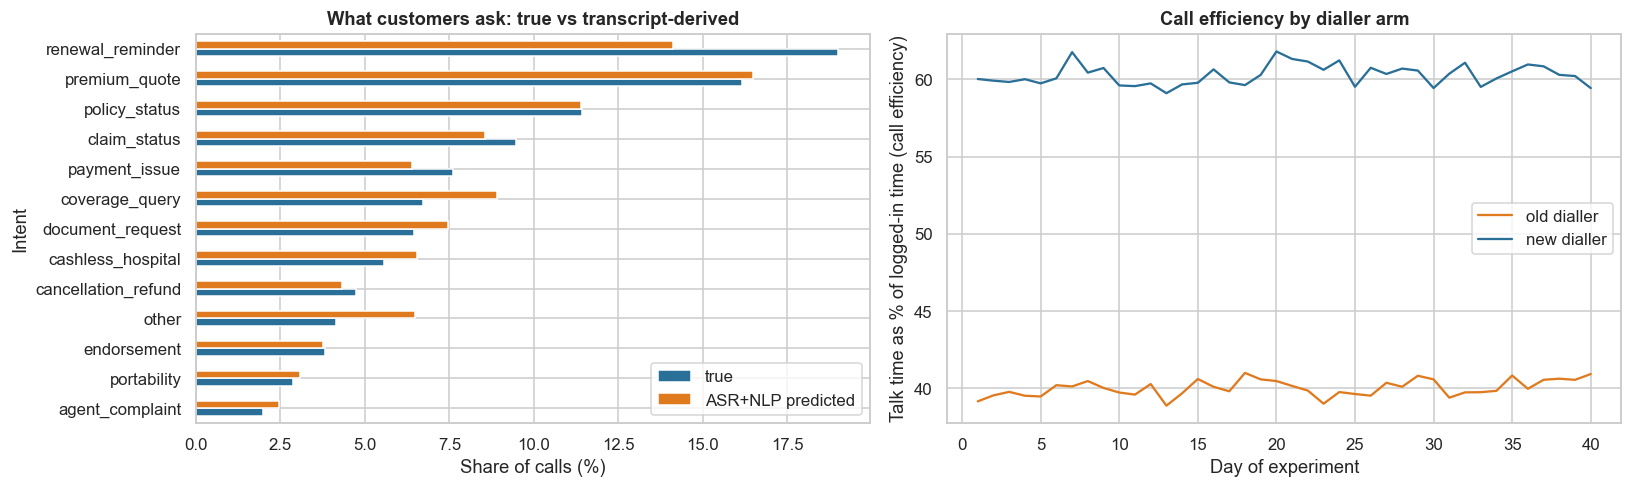

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
tc, pc = cl._true_intent.value_counts(), cl.predicted_intent.value_counts(); fr = pd.DataFrame({"true": tc, "ASR+NLP predicted": pc}).fillna(0) / len(cl) * 100
fr = fr.sort_values("true"); fr.plot(kind="barh", ax=axes[0], color=["#2a6f97", "#e07a1f"]); axes[0].set_xlabel("Share of calls (%)"); axes[0].set_ylabel("Intent"); axes[0].set_title("What customers ask: true vs transcript-derived")
tm = dl.groupby(["day", "new_dialler"]).talk_share.mean().unstack() * 100
axes[1].plot(tm.index, tm[0], color="#e07a1f", label="old dialler"); axes[1].plot(tm.index, tm[1], color="#2a6f97", label="new dialler")
axes[1].set_xlabel("Day of experiment"); axes[1].set_ylabel("Talk time as % of logged-in time (call efficiency)"); axes[1].set_title("Call efficiency by dialler arm"); axes[1].legend()
plt.tight_layout(); plt.show()

**Takeaway:** **left:** the transcript-derived shares (orange) track the true shares (blue) closely for most intents, but over-count some ("coverage query", "other") and under-count others (renewal reminders). **Right:** call efficiency (talk time as a share of logged-in time) sits near 40% for the old dialler and near 60% for the new one on every day of the experiment: a stable, persistent gap, not a one-off.

## 7. Statistical Analysis (core section)

### 7.1 How accurate is the intent tagging, and for whom?

Accuracy and macro-F1 (bootstrap CIs) against the true intent (here from the hidden truth; in practice a QA-labelled sample). Accuracy **by language** with Wilson CIs and a χ² test (H1), plus per-intent F1 for the intents that matter most.

In [7]:
yt, yp = cl._true_intent.values, cl.predicted_intent.values
bs = [accuracy_score(yt[i], yp[i]) for i in (RNG.integers(0, len(yt), len(yt)) for _ in range(300))]
print(f"Overall intent accuracy {accuracy_score(yt, yp):.1%} (bootstrap CI {np.percentile(bs, 2.5):.1%}–{np.percentile(bs, 97.5):.1%}); macro-F1 {f1_score(yt, yp, average='macro'):.3f}")
la = cl.assign(ok=(yt == yp)).groupby("language").ok.agg(["mean", "sum", "size"]); ci = [proportion_confint(r["sum"], r["size"], method="wilson") for _, r in la.iterrows()]; la["CI low"], la["CI high"] = [c[0] for c in ci], [c[1] for c in ci]
c2 = stats.chi2_contingency(pd.crosstab(cl.language, yt == yp)); print(f"Accuracy by language: χ² = {c2[0]:.0f}, p = {c2[1]:.2g}")
f1 = pd.Series(f1_score(yt, yp, average=None, labels=gen.INTENTS), index=gen.INTENTS, name="F1")
display(la.round(4)); f1.sort_values().round(3).to_frame()

Overall intent accuracy 70.2% (bootstrap CI 69.9%–70.6%); macro-F1 0.688
Accuracy by language: χ² = 1421, p = 2.2e-309


,mean,sum,size,CI low,CI high
language,,,,,
english,0.8120,12290,15136,0.8057,0.8181
hindi,0.6368,17028,26742,0.6310,0.6425
hinglish,0.7067,12631,17872,0.7000,0.7134


,F1
coverage_query,0.5980
agent_complaint,0.6300
cashless_hospital,0.6350
document_request,0.6380
portability,0.6610
other,0.6790
premium_quote,0.6890
policy_status,0.6920
endorsement,0.7100
cancellation_refund,0.7190


**(c)/(f) Observation:** overall intent accuracy is **70.2%** (bootstrap CI 69.9–70.6%, macro-F1 0.69). Accuracy depends strongly on language (χ² = 1,421, p ≈ 0): **English 81.2%, Hinglish 70.7%, Hindi 63.7%**. The hardest intents are coverage queries (F1 0.60), agent complaints and cashless hospital (0.64). **(f) Business meaning:** the model is good enough to rank topics and flag trends, but not to count individual calls, and Hindi, the largest language, needs the most work. The documented WER was not disclosed; measure it by language on a labelled sample.

### 7.2 Is "cashless hospital is 7th–8th" a reliable finding? Ranking uncertainty and misclassification correction

The product decision rested on a **frequency rank**. Two problems: (1) sampling noise in ranks; (2) **misclassification bias**: classifier confusions shift counts between intents. We (a) bootstrap the **rank of each intent**, and (b) correct the predicted shares using the confusion matrix estimated on a labelled sample of 3,000 calls: if p̂ = M p (M = P(predicted ∣ true)), then p = M⁻¹ p̂ (projected onto the simplex), with bootstrap CIs.

In [8]:
INT = gen.INTENTS; k = len(INT); lab_idx = RNG.choice(len(cl), 3000, replace=False)
def est_M(t, p):
    M = np.zeros((k, k))
    for i, ti in enumerate(INT):
        m = t == ti; M[:, i] = [(p[m] == pj).mean() if m.sum() else 0 for pj in INT]
    return M
def corrected(pshare, M):
    x = np.linalg.lstsq(M, pshare, rcond=None)[0]; x = np.clip(x, 0, None); return x / x.sum()
M = est_M(yt[lab_idx], yp[lab_idx]); p_hat = np.array([(yp == i).mean() for i in INT]); p_corr = corrected(p_hat, M); p_true = np.array([(yt == i).mean() for i in INT])
rank_bs, corr_bs = [], []
for _ in range(300):
    i = RNG.integers(0, len(yp), len(yp)); ph = np.array([(yp[i] == j).mean() for j in INT]); rank_bs.append(stats.rankdata(-ph)); j = RNG.choice(lab_idx, 3000)
    corr_bs.append(corrected(ph, est_M(yt[j], yp[j])))
rank_bs, corr_bs = np.array(rank_bs), np.array(corr_bs); ci_i = INT.index("cashless_hospital")
tab = pd.DataFrame({"true share": p_true * 100, "predicted share": p_hat * 100, "corrected share": p_corr * 100, "corrected CI low": np.percentile(corr_bs, 2.5, 0) * 100, "corrected CI high": np.percentile(corr_bs, 97.5, 0) * 100,
                    "rank (true)": stats.rankdata(-p_true), "rank (predicted)": stats.rankdata(-p_hat), "rank CI (predicted)": [f"{int(np.percentile(rank_bs[:, j], 2.5))}–{int(np.percentile(rank_bs[:, j], 97.5))}" for j in range(k)]}, index=INT)
print(f"Cashless hospital: true rank {int(stats.rankdata(-p_true)[ci_i])}, predicted rank {int(stats.rankdata(-p_hat)[ci_i])} (95% bootstrap range {np.percentile(rank_bs[:, ci_i], 2.5):.0f}–{np.percentile(rank_bs[:, ci_i], 97.5):.0f}); "
      f"share: true {p_true[ci_i] * 100:.2f}%, predicted {p_hat[ci_i] * 100:.2f}%, corrected {p_corr[ci_i] * 100:.2f}% (CI {np.percentile(corr_bs[:, ci_i], 2.5) * 100:.2f}–{np.percentile(corr_bs[:, ci_i], 97.5) * 100:.2f}%)")
tab.sort_values("true share", ascending=False).round(3)

Cashless hospital: true rank 8, predicted rank 7 (95% bootstrap range 7–9); share: true 5.57%, predicted 6.53%, corrected 6.50% (CI 5.08–7.94%)


,true share,predicted share,corrected share,corrected CI low,corrected CI high,rank (true),rank (predicted),rank CI (predicted)
renewal_reminder,19.0030,14.1320,18.5160,17.3800,19.7510,1.0000,2.0000,2–2
premium_quote,16.1510,16.4970,16.2960,14.2500,18.1040,2.0000,1.0000,1–1
policy_status,11.4330,11.3920,10.1690,8.6950,11.6390,3.0000,3.0000,3–3
claim_status,9.4860,8.5570,8.4240,6.8880,9.8690,4.0000,5.0000,5–5
payment_issue,7.6230,6.3930,7.5190,6.7210,8.3310,5.0000,9.0000,7–9
coverage_query,6.7130,8.9220,7.2650,5.8460,9.0540,6.0000,4.0000,4–4
document_request,6.4400,7.4580,7.4110,6.0780,8.7720,7.0000,6.0000,6–6
cashless_hospital,5.5670,6.5340,6.4960,5.0810,7.9400,8.0000,7.0000,7–9
cancellation_refund,4.7450,4.3380,5.8300,4.8690,6.9080,9.0000,10.0000,10–10
other,4.1510,6.4820,4.7990,3.8440,5.5810,10.0000,8.0000,7–9


**Observation:** the finding that cashless-hospital requests are mid-ranked survives uncertainty: **true rank 8, predicted rank 7 (95% bootstrap range 7–9)**, matching the documented "7th–8th". Shares are biased: **predicted 6.53% vs true 5.57%** (the classifier confuses it with claim status). The matrix-inversion correction gives 6.50% (CI 5.08–7.94%); it contains the truth, but did not remove the bias here. The correction worked well for some classes (e.g., renewal reminders 14.1% predicted → 18.5% corrected vs 19.0% true) and not for others. **Business meaning:** rank and trend are reliable, but exact shares are not. If a product decision depends on a *level* (e.g., a business case for 5% of calls), validate it on a labelled sample.

### 7.3 Is the request really growing? Trend test on a rising intent

Cashless-hospital requests rise over the 12 weeks. We test the trend in the **weekly share** with a **Cochran–Armitage** trend test on (a) predicted and (b) misclassification-corrected counts, and fit a log-linear weekly growth rate.

Cochran–Armitage trend on predicted counts: z = 10.1, p = 4.2e-24 | on true counts: z = 15.2, p = 4e-52 | log-linear growth of predicted share = +4.7% per week


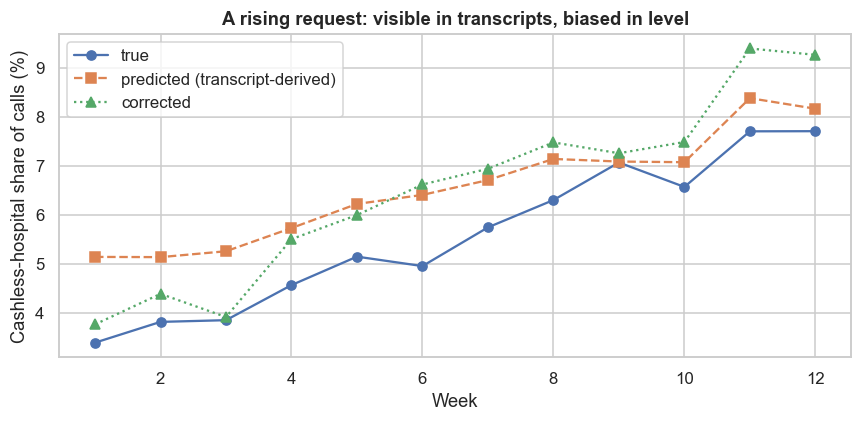

,calls,predicted share,corrected share,true share
week,,,,
1,4979,0.0514,0.0377,0.0339
2,5003,0.0514,0.0439,0.0382
3,4984,0.0526,0.0392,0.0385
4,4992,0.0573,0.0550,0.0457
5,4935,0.0622,0.0599,0.0515
6,4965,0.0640,0.0662,0.0495
7,4980,0.0671,0.0694,0.0574
8,5016,0.0714,0.0747,0.0630
9,5025,0.0708,0.0725,0.0706


In [9]:
rows = []
for w in range(1, 13):
    s = cl[cl.week == w]; ph = np.array([(s.predicted_intent == j).mean() for j in INT]); pc_ = corrected(ph, M)
    rows.append((w, len(s), ph[ci_i], pc_[ci_i], (s._true_intent == "cashless_hospital").mean()))
tw = pd.DataFrame(rows, columns=["week", "calls", "predicted share", "corrected share", "true share"]).set_index("week")
def ca(x_succ, n_tot):
    x = np.arange(len(n_tot)); p = x_succ.sum() / n_tot.sum(); xb = (x * n_tot).sum() / n_tot.sum()
    T = (x * (x_succ - n_tot * p)).sum() / np.sqrt(p * (1 - p) * (n_tot * (x - xb) ** 2).sum()); return T, 2 * stats.norm.sf(abs(T))
T_p, p_p = ca((tw["predicted share"] * tw.calls).values, tw.calls.values); T_t, p_t = ca((tw["true share"] * tw.calls).values, tw.calls.values)
g = stats.linregress(tw.index, np.log(tw["predicted share"]))
print(f"Cochran–Armitage trend on predicted counts: z = {T_p:.1f}, p = {p_p:.2g} | on true counts: z = {T_t:.1f}, p = {p_t:.2g} | log-linear growth of predicted share = {np.exp(g.slope) - 1:+.1%} per week")
fig, ax = plt.subplots(figsize=(8, 4)); ax.plot(tw.index, tw["true share"] * 100, "o-", label="true"); ax.plot(tw.index, tw["predicted share"] * 100, "s--", label="predicted (transcript-derived)"); ax.plot(tw.index, tw["corrected share"] * 100, "^:", label="corrected")
ax.set_xlabel("Week"); ax.set_ylabel("Cashless-hospital share of calls (%)"); ax.set_title("A rising request: visible in transcripts, biased in level"); ax.legend(); plt.tight_layout(); plt.show()
tw.round(4)

**Takeaway:** the cashless-hospital share rises from ≈ 3.4% (week 1) to 7.7% (week 12) in truth (Cochran–Armitage z = 15.2, p ≈ 5e-52), and the transcript-derived share shows the same rise (z = 10.1, p ≈ 4e-24; **+4.7% per week**) from 5.1% to 8.2%. The corrected share follows the truth more closely over time but is biased upwards in level. **Business meaning:** the trend is detectable in the data you actually have, quickly (weekly, from 5,000 calls), which is exactly what a product team needs to prioritise a cashless-hospital feature.

### 7.4 Compliance monitoring: from 1–2% sampling to 100% monitoring

On the 8,000-call QA audit, the model's breach score is evaluated with **ROC-AUC** and **precision–recall**. The operational question is an **alert budget**: QA staff can re-listen to a fixed number of flagged calls. For several budgets we report precision (share of alerts that are true breaches, Wilson CI), recall (share of all breaches caught), and the comparison with **random sampling at the old 1–2% rate**. We also test whether performance differs by language (AUC, DeLong-style bootstrap).

In [10]:
y, s = qa.qa_breach.values, qa.model_breach_score.values; auc = roc_auc_score(y, s)
rows = []
for bud in (0.01, 0.02, 0.05, 0.10, 0.20):
    k_ = int(bud * len(y)); top = np.argsort(-s)[:k_]; tp = y[top].sum(); lo, hi = proportion_confint(tp, k_, method="wilson")
    rows.append((f"{bud:.0%}", k_, tp / k_, lo, hi, tp / y.sum(), y.mean(), bud))
bd = pd.DataFrame(rows, columns=["alert budget (share of calls)", "alerts", "precision", "CI low", "CI high", "recall (breaches caught)", "precision of random sampling", "recall of random sampling"]).set_index("alert budget (share of calls)")
la2 = {}
for l_, g_ in qa.groupby("language"):
    a_ = roc_auc_score(g_.qa_breach, g_.model_breach_score); bs_ = [roc_auc_score(g_.qa_breach.values[i], g_.model_breach_score.values[i]) for i in (RNG.integers(0, len(g_), len(g_)) for _ in range(200))]
    la2[l_] = (a_, np.percentile(bs_, 2.5), np.percentile(bs_, 97.5))
print(f"Breach base rate {y.mean():.1%} | model ROC-AUC {auc:.3f} | AUC by language: " + ", ".join(f"{k} {v[0]:.3f} ({v[1]:.3f}–{v[2]:.3f})" for k, v in la2.items()))
bd.round(4)

Breach base rate 6.4% | model ROC-AUC 0.915 | AUC by language: english 0.920 (0.897–0.944), hindi 0.924 (0.906–0.941), hinglish 0.900 (0.873–0.927)


,alerts,precision,CI low,CI high,recall (breaches caught),precision of random sampling,recall of random sampling
alert budget (share of calls),,,,,,,
1%,80,0.9000,0.8149,0.9485,0.1398,0.0644,0.0100
2%,160,0.8188,0.7518,0.8707,0.2544,0.0644,0.0200
5%,400,0.6200,0.5715,0.6662,0.4816,0.0644,0.0500
10%,800,0.4375,0.4035,0.4721,0.6796,0.0644,0.1000
20%,1600,0.2650,0.2440,0.2872,0.8233,0.0644,0.2000


**Observation:** with a base rate of 6.4% breaches, the model's score has **ROC-AUC 0.915** (English 0.920, Hindi 0.924, Hinglish 0.900: no meaningful language gap, CIs overlap). By alert budget:
- **1% of calls** (80 alerts): precision **90%**, 14% of breaches caught.
- **2%:** precision 82%, 25% caught.
- **5%:** precision **62%**, **48% caught**.
- **10%:** precision 44%, 68% caught.
- **20%:** precision 27%, 82% caught.

**Random listening at the same budgets** has 6.4% precision and catches only 1%, 2%, 5%, 10%, 20% of breaches. **Business meaning:** flagging concentrates QA time on the calls that matter: at a 5% budget, a QA analyst finds a real breach in about 6 of every 10 flagged calls, instead of 1 in 16.

### 7.5 The dialler experiment: cluster-randomised, analysed at the team level

**(a) Why not just compare agent-days?** Teams, not agents, were randomised. Agents in a team share a supervisor and call list, so their days are **correlated**. Treating 4,800 agent-days as independent would make the result look far more certain than it is. The correct unit is the **team** (24 of them).

**Analyses:**
1. **Team-level means** with a **permutation test** (relabel which teams were "new", 10,000 times) and a Welch t-test on the 24 team means.
2. **Cluster-robust regression** (SEs clustered by team) on agent-day outcomes, with day fixed effects.
3. **ICC** and **design effect** (how much clustering inflates the variance), both estimated **after removing the arm effect**, so that the treatment difference is not mistaken for team-to-team variation.
4. Outcomes: dials per hour, talk-time share, connect rate, sales per logged-in hour (and callback delay).

In [11]:
tm = dl.groupby(["team_id", "new_dialler"]).agg(dials_per_hr=("dials_per_hr", "mean"), talk_share=("talk_share", "mean"), connect_rate=("connect_rate", "mean"), sales_per_hr=("sales_per_hr", "mean"),
                                                   callback_delay=("avg_callback_delay_min", "mean")).reset_index()
outs = ["dials_per_hr", "talk_share", "connect_rate", "sales_per_hr", "callback_delay"]; rows = []
for o in outs:
    a1, a0 = tm.loc[tm.new_dialler == 1, o].values, tm.loc[tm.new_dialler == 0, o].values; obs = a1.mean() - a0.mean(); pooled = tm[o].values; lab = tm.new_dialler.values
    perm = np.array([(lambda l: pooled[l == 1].mean() - pooled[l == 0].mean())(RNG.permutation(lab)) for _ in range(10000)]); pp = (np.abs(perm) >= abs(obs)).mean()
    w = stats.ttest_ind(a1, a0, equal_var=False); icc_m = smf.mixedlm(f"{o} ~ new_dialler", data=dl, groups=dl.team_id).fit(); icc = icc_m.cov_re.iloc[0, 0] / (icc_m.cov_re.iloc[0, 0] + icc_m.scale)
    cr = smf.ols(f"{o} ~ new_dialler + C(day)", data=dl).fit(cov_type="cluster", cov_kwds={"groups": dl.team_id}); ci = cr.conf_int().loc["new_dialler"]
    rows.append((o, a0.mean(), a1.mean(), obs / a0.mean(), pp, w.pvalue, cr.params["new_dialler"], ci[0], ci[1], icc, 1 + (dl.groupby("team_id").size().mean() - 1) * icc))
dx = pd.DataFrame(rows, columns=["outcome", "old dialler (team mean)", "new dialler", "relative change", "permutation p", "Welch p (24 teams)", "cluster-robust effect", "CI low", "CI high", "ICC", "design effect"]).set_index("outcome")
naive = smf.ols("sales_per_hr ~ new_dialler + C(day)", data=dl).fit(); print(f"Naive SE for the sales effect (treating agent-days as independent) = {naive.bse['new_dialler']:.4f} vs cluster-robust {smf.ols('sales_per_hr ~ new_dialler + C(day)', data=dl).fit(cov_type='cluster', cov_kwds={'groups': dl.team_id}).bse['new_dialler']:.4f}")
dx.round(4)

Naive SE for the sales effect (treating agent-days as independent) = 0.0065 vs cluster-robust 0.0140


,old dialler (team mean),new dialler,relative change,permutation p,Welch p (24 teams),cluster-robust effect,CI low,CI high,ICC,design effect
outcome,,,,,,,,,,
dials_per_hr,18.0265,23.8856,0.3250,0.0000,0.0000,5.8613,5.5933,6.1293,0.0000,1.0000
talk_share,0.4002,0.6027,0.5059,0.0000,0.0000,0.2024,0.1808,0.2240,0.2099,42.2473
connect_rate,0.2628,0.3039,0.1567,0.0000,0.0000,0.0412,0.0346,0.0478,0.0000,1.0000
sales_per_hr,0.2681,0.4442,0.6567,0.0000,0.0000,0.1762,0.1487,0.2037,0.0228,5.4834
callback_delay,294.8021,44.8118,-0.8480,0.0000,0.0000,-250.0507,-254.8937,-245.2077,0.0000,1.0000


**(c)/(f) Observation:** the experiment shows large, clear effects at the team level (24 teams; permutation p < 0.0001 for all outcomes):
- **Dials per hour:** 18.0 → **23.9 (+32.5%)**, vs the documented "+50% dial-out rate".
- **Talk-time share:** 40.0% → **60.3% (+51%)** (documented 40% → 85%).
- **Connect rate:** 26.3% → 30.4% (+16%).
- **Sales per logged-in hour:** 0.268 → **0.444 (+66%)** (cluster-robust effect +0.176, CI 0.149–0.204).
- **Callback delay:** 295 → 45 minutes (−85%; documented 30–45 minutes ✓).

**Clustering matters.** Treating agent-days as independent gives a standard error of 0.0065 for the sales effect, but the cluster-robust one is **0.0140 (2.2× larger)**. After removing the arm effect, the **ICC** is 0.21 for talk-time share and only 0.02 for sales per hour, which gives a design effect of 42 and 5.5 respectively: the effective number of independent observations is far smaller than 4,740. **Business meaning:** the effects are large enough to be convincing even with the correct (team-level) analysis.

### 7.6 Callbacks and customer experience

The documented callback time of 30–45 minutes. We compare the average callback delay (log-scale, team means; Mann–Whitney across teams) and the share of agent-days with a callback delay under 60 minutes, and check whether faster callbacks go with more sales (a team-level correlation, descriptive only).

In [12]:
cb = tm.assign(l=np.log(tm.callback_delay)); a1, a0 = cb.loc[cb.new_dialler == 1, "callback_delay"], cb.loc[cb.new_dialler == 0, "callback_delay"]; mw = stats.mannwhitneyu(a1, a0)
u60 = dl.groupby("new_dialler").avg_callback_delay_min.apply(lambda s: (s < 60).mean())
print(f"Median callback delay: old {dl.loc[dl.new_dialler == 0, 'avg_callback_delay_min'].median():.0f} min vs new {dl.loc[dl.new_dialler == 1, 'avg_callback_delay_min'].median():.0f} min (team-level Mann–Whitney p = {mw.pvalue:.2g}); "
      f"agent-days with callback < 60 min: {u60[0]:.0%} → {u60[1]:.0%}")
r_, p_ = stats.spearmanr(tm.callback_delay, tm.sales_per_hr); print(f"Team-level Spearman(callback delay, sales per hour) = {r_:+.2f} (p = {p_:.2g}); mostly reflects the arm, since arms differ in both")

Median callback delay: old 259 min vs new 40 min (team-level Mann–Whitney p = 3.7e-05); agent-days with callback < 60 min: 0% → 79%
Team-level Spearman(callback delay, sales per hour) = -0.71 (p = 0.00011); mostly reflects the arm, since arms differ in both


**Observation:** callback delays fall from a median of **259 to 40 minutes** (team-level Mann–Whitney p < 0.0001), and agent-days with callbacks within an hour rise from **0% to 79%**. Teams with faster callbacks have higher sales per hour (Spearman −0.71, p = 0.0001), but that largely reflects the arm, since the new dialler improved both. **Business meaning:** the documented callback target of 30–45 minutes is achieved, and faster callbacks are one plausible mechanism for the sales gain (consistent with Case 28's speed-to-lead result).

### 7.7 How many teams do we need next time?

With cluster randomisation, power depends on the **number of teams** and the ICC, not on agent-days. From the observed between-team SD of the team-level outcome, we compute teams per arm for 80% power (α = 0.05, two-sided).

In [13]:
rows = []
for o, rel in (("talk_share", 0.10), ("talk_share", 0.25), ("sales_per_hr", 0.10), ("sales_per_hr", 0.25), ("dials_per_hr", 0.10)):
    sd = tm.groupby("new_dialler")[o].std().mean(); base = tm.loc[tm.new_dialler == 0, o].mean(); n = int(np.ceil(2 * (1.96 + 0.84) ** 2 * sd ** 2 / (rel * base) ** 2)); rows.append((o, f"{rel:.0%}", n, max(n, 3)))
pd.DataFrame(rows, columns=["outcome", "relative effect to detect", "teams per arm (formula)", "teams per arm (practical floor of 3)"]).set_index(["outcome", "relative effect to detect"])

teams per arm (formula)  teams per arm (practical floor of 3)
outcome      relative effect to detect                                                               
talk_share   10%                                              8                                     8
             25%                                              2                                     3
sales_per_hr 10%                                             23                                    23
             25%                                              4                                     4
dials_per_hr 10%                                              1                                     3

**Observation:** with effects as large as these, few teams are needed: **8 per arm** to detect a 10% change in call efficiency, **23 per arm** for a 10% change in sales per hour, and **3–4 per arm** for 25% effects (the practical floor is 3 teams, since a standard deviation cannot be estimated from one or two). **Business meaning:** the 24-team experiment was well powered for the large effects seen here. Detecting a modest 10% improvement in *sales* would need roughly all 24 teams per arm, so test future incremental tweaks with stepped-wedge or longer designs.

## 8. ML Section — not reproduced; what to validate

The proprietary Hindi ASR and NLP models are not reproduced (no audio, no deep-learning framework in the library list). The decision-relevant statistics (intent accuracy by language, corrected counts, flag precision at an alert budget, a randomised dialler test) are model-agnostic. In production, add: **WER by language/accent/noise on a labelled sample**, a **drift monitor** (new products and slang change vocabulary), and **fairness checks** (compliance flags should not over-trigger for particular accents or languages).

## 9. Business Translation — ₹ impact

Assumptions (D-27-07):
- 400 outbound agents; 26 working days a month; agent cost ₹35,000 a month.
- Each sale earns ₹1,800 margin.
- QA: a reviewer re-listens at 5 minutes per flagged call; ₹400 per hour.

In [14]:
AG, DAYS, COST, MARG = 400, 26, 35000, 1800
s0, s1 = dl.loc[dl.new_dialler == 0, "sales"].mean(), dl.loc[dl.new_dialler == 1, "sales"].mean(); gain = AG * DAYS * (s1 - s0) * MARG
pe = dx.loc["sales_per_hr"]; lo_g, hi_g = AG * DAYS * 8 * pe["CI low"] * MARG, AG * DAYS * 8 * pe["CI high"] * MARG
print(f"Sales per agent-day: old {s0:.2f} vs new {s1:.2f} → extra margin ≈ ₹{gain / 1e7:.1f} crore/month for 400 agents (cluster-robust 95% range ≈ ₹{lo_g / 1e7:.1f}–{hi_g / 1e7:.1f} crore)")
print(f"Equivalent to {AG * (s1 / s0 - 1):.0f} extra agents' output ≈ ₹{AG * (s1 / s0 - 1) * COST / 1e7:.1f} crore/month of salary avoided")
k_ = int(0.05 * 1e6); qa_cost = k_ * 5 / 60 * 400
print(f"QA at a 5% alert budget on 10 lakh calls/month: {k_:,} alerts, ≈ {k_ * bd.loc['5%', 'precision']:,.0f} true breaches found (random 1–2% sampling would find ≈ {1e6 * 0.015 * y.mean():,.0f} breaches at 6.4% precision); QA cost ≈ ₹{qa_cost / 1e7:.2f} crore/month")

Sales per agent-day: old 2.14 vs new 3.55 → extra margin ≈ ₹2.6 crore/month for 400 agents (cluster-robust 95% range ≈ ₹2.2–3.1 crore)


Equivalent to 263 extra agents' output ≈ ₹0.9 crore/month of salary avoided
QA at a 5% alert budget on 10 lakh calls/month: 50,000 alerts, ≈ 31,000 true breaches found (random 1–2% sampling would find ≈ 966 breaches at 6.4% precision); QA cost ≈ ₹0.17 crore/month


**Takeaway (business reading):** for **400 outbound agents** (26 working days a month, ₹1,800 margin per sale, ₹35,000 a month per agent):
- **Sales per agent-day:** 2.14 → 3.55: ≈ **₹2.6 crore/month** of extra margin (cluster-robust 95% range ₹2.2–3.1 crore), equal to the output of ≈ 263 extra agents (≈ ₹0.9 crore/month of salary).
- **QA at a 5% alert budget** on 10 lakh calls: 50,000 alerts and ≈ **31,000 true breaches found** for ≈ ₹0.17 crore of QA time (₹400/hour, 5 minutes per call), versus ≈ **970 breaches** under 1–2% random listening.
- **Reading:** the dialler change adds the most direct revenue; the compliance monitoring avoids regulatory and mis-selling risk that is not valued here. The intent analysis informs product choices (cashless hospital) whose value is not quantified.

## 10. Recommendation and Decision

**Decision against the hypotheses:**
- **H1 ✅:** intent accuracy differs strongly by language.
- **H2 ✅:** cashless-hospital share is rising (+4.7% per week).
- **H3 ✅:** the compliance flag is far above the 6.4% base rate (62% precision at a 5% budget).
- **H4 ✅:** the new dialler improves efficiency and sales (team-level p < 0.0001).

**I recommend:**
1. **Roll out the new dialler** to all teams, with the callback-scheduling feature.
2. **Run compliance QA on flagged calls** at a fixed budget (start at 2–5% of calls, 82–62% precision), with analysts feeding labels back to the model.
3. **Use transcript-based intent counts for ranking and trends**, not exact levels. Re-estimate the confusion correction monthly, and invest in Hindi accuracy (64%).
4. **Design future dialler tests at the team level** (or stepped-wedge) with cluster-robust analysis. Never analyse agent-days as independent.
5. **Guardrails:** monitor spam/complaint rates (TRAI/DND call-time rules) alongside call efficiency.

**KPIs:** WER and intent accuracy by language; breach-flag precision and recall at the alert budget; dials/hour, talk-time share, sales per logged-in hour (team-level); callback delay; share of calls monitored.

## 11. Risks, Limitations and Next Steps

- **Simulated ASR/NLP:** error structure and WER are assumed. Measure WER on real labelled Hindi/Hinglish telephony audio, because accent and call-quality effects are large.
- **Correction needs a representative labelled sample:** the confusion-matrix correction (7.2) assumes the error pattern is the same in labelled and unlabelled calls. Re-estimate it as the product mix changes.
- **Cluster trials are expensive in teams:** with 24 teams the dialler test detects only fairly large effects (7.7). Stepped-wedge rollouts (teams switching at random times) give more power.
- **Efficiency vs conversion:** more dials and more talk time are mechanism metrics. The business metric is sales per hour and customer experience (complaints, opt-outs). Watch spam-call complaints and RBI/TRAI call-time rules.
- **Privacy:** call recording and transcript analytics need consent notices and retention limits under the DPDP Act and IRDAI norms.

## 12. Appendix

| Quantity | Formula |
|---|---|
| Misclassification correction | p̂ = M·p → p = M⁻¹·p̂ (projected to the simplex) |
| Cochran–Armitage | z = Σ xᵢ(sᵢ − nᵢp̄) / √(p̄(1 − p̄)Σnᵢ(xᵢ − x̄)²) |
| Precision / recall at budget b | true breaches in the top b·N / (b·N); / all breaches |
| ICC | σ²_team / (σ²_team + σ²_within) |
| Design effect | 1 + (m − 1)·ICC, m = observations per cluster |
| Teams needed per arm | n = 2(z₀.₉₇₅ + z₀.₈)² σ²_team / Δ² |

| Term | Meaning |
|---|---|
| ASR / WER | Automatic speech recognition / word error rate |
| Intent | The purpose of a call (e.g., claim status, cashless hospital) |
| Predictive dialler | Software that dials ahead and connects only answered calls to free agents |
| Call efficiency | Talk time as a share of logged-in time |
| Cluster randomisation | Randomising whole teams, not individuals |
| ICC | How similar observations within a team are |